# ResNet-18 compression baseline

Manuscript section 3.5.2: train a ResNet-18 baseline on the harmonized images, then measure how its
accuracy drops under social-media compression (clean vs JPEG 90/70/50/30, WebP, downscaling,
repeated recompression). ΔA = A_clean − A_compressed is the baseline the multi-signal framework
is compared against.

Before starting: **Runtime > Change runtime type > T4 GPU**, and run notebook 01 through step 8 once
so the prepared data is saved on Google Drive.

## 1. Get the code and check the GPU

In [1]:
!git clone https://github.com/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution.git repo
%cd repo
!pip install -q -e ".[train,dev]"
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (training will be very slow)")

Cloning into 'repo'...
remote: Enumerating objects: 439, done.
remote: Counting objects: 100% (203/203), done.
remote: Compressing objects: 100% (150/150), done.
remote: Total 439 (delta 118), reused 73 (delta 44), pack-reused 236 (from 1)
Receiving objects: 100% (439/439), 6.08 MiB | 12.89 MiB/s, done.
Resolving deltas: 100% (218/218), done.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for attribution (pyproject.toml) ... done
GPU: Tesla T4


## 2. Restore the prepared data from Google Drive

In [2]:
from google.colab import drive
import os
drive.mount("/content/drive")
ZIP = "/content/drive/MyDrive/thesis-data/harmonized.zip"
if not os.path.exists(ZIP):
    raise FileNotFoundError(f"{ZIP} not found: run notebook 01 through step 8 first, it saves the prepared data there")
!unzip -qo $ZIP -d .
!wc -l data/harmonized/train.csv data/harmonized/val.csv data/harmonized/test.csv

Mounted at /content/drive
  13849 data/harmonized/train.csv
   2981 data/harmonized/val.csv
   2993 data/harmonized/test.csv
  19823 total


## 3. Train ResNet-18
Up to 50 epochs with early stopping (stops after 5 epochs without validation improvement).
Each epoch prints training loss, validation loss and validation accuracy. Checkpoints are
written to Google Drive as well, so a disconnect doesn't lose the model.

In [3]:
!mkdir -p /content/drive/MyDrive/thesis-data/models && rm -rf outputs/models && ln -s /content/drive/MyDrive/thesis-data/models outputs/models
!python scripts/train.py --arch resnet18

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 187MB/s]
training resnet18 on cuda: 13848 train / 2980 val images
epoch 1: train_loss=0.3649 val_loss=0.2628 val_acc=0.8886
epoch 2: train_loss=0.2570 val_loss=0.2892 val_acc=0.8815
epoch 3: train_loss=0.2107 val_loss=0.2775 val_acc=0.8903
epoch 4: train_loss=0.1841 val_loss=0.2555 val_acc=0.8909
epoch 5: train_loss=0.1548 val_loss=0.2622 val_acc=0.9077
epoch 6: train_loss=0.1338 val_loss=0.2795 val_acc=0.8966
epoch 7: train_loss=0.1230 val_loss=0.2969 val_acc=0.8913
epoch 8: train_loss=0.1085 val_loss=0.2698 val_acc=0.9060
epoch 9: train_loss=0.0925 val_loss=0.2715 val_acc=0.9141
early stop: no val improvement for 5 epochs
saved outputs/models/resnet18/best.pt, temperature=1.410


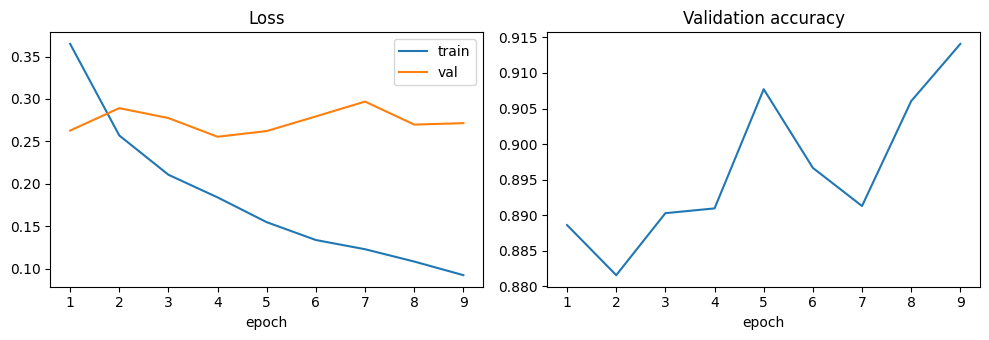

In [4]:
import json, matplotlib.pyplot as plt
h = json.load(open("outputs/models/resnet18/history.json"))
ep = [r["epoch"] for r in h]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(ep, [r["train_loss"] for r in h], label="train"); axes[0].plot(ep, [r["val_loss"] for r in h], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(ep, [r["val_acc"] for r in h]); axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("epoch")
plt.tight_layout()

## 4. Compression stress test
Evaluates the best checkpoint on the test split under every transformation in the config.
Results go to `outputs/stress_test/resnet18/results.csv`.

In [5]:
!mkdir -p /content/drive/MyDrive/thesis-data/stress_test && rm -rf outputs/stress_test && ln -s /content/drive/MyDrive/thesis-data/stress_test outputs/stress_test
!python scripts/stress_test.py --arch resnet18

         clean: acc=0.9041 f1=0.9025 fpr=0.0814 ece=0.0163
      jpeg_q90: acc=0.8743 f1=0.8704 fpr=0.0974 ece=0.0189
      jpeg_q70: acc=0.8449 f1=0.8330 fpr=0.0854 ece=0.0397
      jpeg_q50: acc=0.8108 f1=0.7882 fpr=0.0841 ece=0.0692
      jpeg_q30: acc=0.7781 f1=0.7402 fpr=0.0781 ece=0.1038
      webp_q80: acc=0.8727 f1=0.8648 fpr=0.0714 ece=0.0203
    resize_0.5: acc=0.8135 f1=0.7772 fpr=0.0254 ece=0.0778
   resize_0.25: acc=0.7122 f1=0.6144 fpr=0.0360 ece=0.1766
 recompress_x3: acc=0.8513 f1=0.8395 fpr=0.0774 ece=0.0378
results: outputs/stress_test/resnet18/results.csv


,condition,accuracy,precision,recall,f1,fpr,ece,delta_a
0,clean,0.9041,0.9159,0.8895,0.9025,0.0814,0.0163,0.0000
1,jpeg_q90,0.8743,0.8964,0.8459,0.8704,0.0974,0.0189,0.0297
2,jpeg_q70,0.8449,0.9004,0.7749,0.8330,0.0854,0.0397,0.0592
3,jpeg_q50,0.8108,0.8931,0.7053,0.7882,0.0841,0.0692,0.0932
4,jpeg_q30,0.7781,0.8899,0.6336,0.7402,0.0781,0.1038,0.1260
5,webp_q80,0.8727,0.9193,0.8165,0.8648,0.0714,0.0203,0.0314
6,resize_0.5,0.8135,0.9624,0.6517,0.7772,0.0254,0.0778,0.0906
7,resize_0.25,0.7122,0.9270,0.4595,0.6144,0.0360,0.1766,0.1918
8,recompress_x3,0.8513,0.9094,0.7796,0.8395,0.0774,0.0378,0.0528


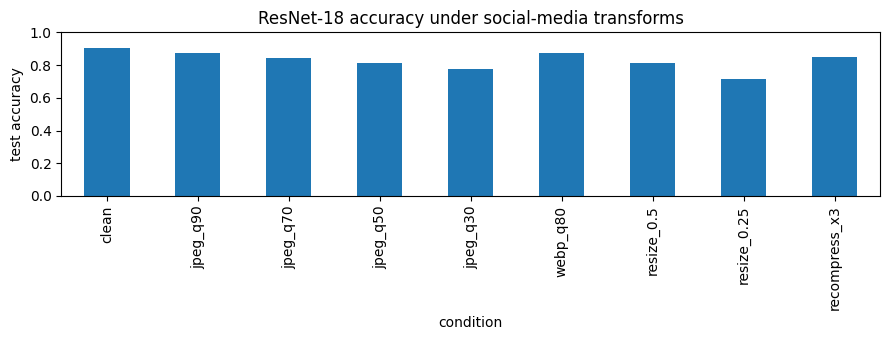

In [6]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("outputs/stress_test/resnet18/results.csv")
display(df.round(4))
ax = df.plot.bar(x="condition", y="accuracy", legend=False, figsize=(9, 3.5), ylim=(0, 1))
ax.set_ylabel("test accuracy"); ax.set_title("ResNet-18 accuracy under social-media transforms")
plt.tight_layout()

## 5. ResNet-50 and EfficientNet-B0
The two main backbones from the manuscript, trained and stress-tested exactly like ResNet-18.
Each takes roughly 10-20 minutes on an L4. Results go to the same Drive folders, one subfolder per model.

In [7]:
# Link outputs to Drive (safe to re-run; needed if you skipped sections 3-4 in this session)
for d in ["models", "stress_test"]:
    !mkdir -p /content/drive/MyDrive/thesis-data/$d && rm -rf outputs/$d && ln -s /content/drive/MyDrive/thesis-data/$d outputs/$d

In [8]:
!python scripts/train.py --arch resnet50
!python scripts/stress_test.py --arch resnet50

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100% 97.8M/97.8M [00:00<00:00, 204MB/s]
training resnet50 on cuda: 13848 train / 2980 val images
epoch 1: train_loss=0.3353 val_loss=0.2553 val_acc=0.8852
epoch 2: train_loss=0.1938 val_loss=0.2190 val_acc=0.9134
epoch 3: train_loss=0.1521 val_loss=0.2100 val_acc=0.9252
epoch 4: train_loss=0.1134 val_loss=0.2412 val_acc=0.9211
epoch 5: train_loss=0.0969 val_loss=0.2310 val_acc=0.9218
epoch 6: train_loss=0.0806 val_loss=0.2197 val_acc=0.9268
epoch 7: train_loss=0.0714 val_loss=0.2816 val_acc=0.9191
epoch 8: train_loss=0.0684 val_loss=0.2512 val_acc=0.9255
early stop: no val improvement for 5 epochs
saved outputs/models/resnet50/best.pt, temperature=1.294
         clean: acc=0.9375 f1=0.9367 fpr=0.0514 ece=0.0251
      jpeg_q90: acc=0.9041 f1=0.9011 fpr=0.0674 ece=0.0172
      jpeg_q70: acc=0.8346 f1=0.8190 fpr=0.0814 ece=0.0351
      jpeg_q50: acc=0.7868 f

In [9]:
!python scripts/train.py --arch efficientnet_b0
!python scripts/stress_test.py --arch efficientnet_b0

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100% 20.5M/20.5M [00:00<00:00, 167MB/s]
training efficientnet_b0 on cuda: 13848 train / 2980 val images
epoch 1: train_loss=0.3601 val_loss=0.2382 val_acc=0.9091
epoch 2: train_loss=0.2215 val_loss=0.1920 val_acc=0.9258
epoch 3: train_loss=0.1700 val_loss=0.1767 val_acc=0.9329
epoch 4: train_loss=0.1298 val_loss=0.1852 val_acc=0.9329
epoch 5: train_loss=0.1059 val_loss=0.1923 val_acc=0.9346
epoch 6: train_loss=0.0860 val_loss=0.2012 val_acc=0.9322
epoch 7: train_loss=0.0765 val_loss=0.1968 val_acc=0.9359
epoch 8: train_loss=0.0645 val_loss=0.2199 val_acc=0.9322
early stop: no val improvement for 5 epochs
saved outputs/models/efficientnet_b0/best.pt, temperature=1.159
         clean: acc=0.9345 f1=0.9344 fpr=0.0660 ece=0.0137
      jpeg_q90: acc=0.9258 f1=0.9245 fpr=0.0587 ece=0.0096
      jpeg_q70: acc=0.8737 f1=0.8630 fp

## 6. Compare all three
Test accuracy and ΔA (A_clean − A_condition) per condition for each backbone.

arch,efficientnet_b0,resnet18,resnet50
condition,,,
clean,0.9345,0.9041,0.9375
jpeg_q90,0.9258,0.8743,0.9041
jpeg_q70,0.8737,0.8449,0.8346
jpeg_q50,0.8372,0.8108,0.7868
jpeg_q30,0.8015,0.7781,0.7500
webp_q80,0.9051,0.8727,0.8920
resize_0.5,0.8222,0.8135,0.8820
resize_0.25,0.6277,0.7122,0.7146
recompress_x3,0.8767,0.8513,0.8409


arch,efficientnet_b0,resnet18,resnet50
condition,,,
clean,0.0000,0.0000,0.0000
jpeg_q90,0.0087,0.0297,0.0334
jpeg_q70,0.0608,0.0592,0.1029
jpeg_q50,0.0973,0.0932,0.1507
jpeg_q30,0.1330,0.1260,0.1875
webp_q80,0.0294,0.0314,0.0455
resize_0.5,0.1123,0.0906,0.0555
resize_0.25,0.3068,0.1918,0.2229
recompress_x3,0.0578,0.0528,0.0966


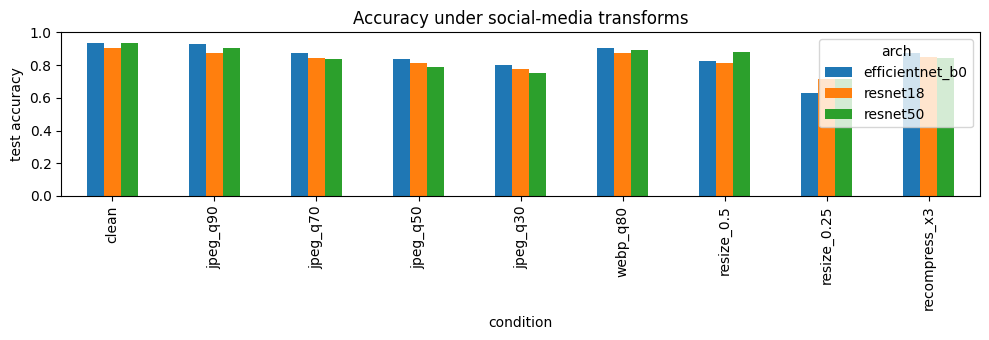

In [10]:
import pandas as pd, matplotlib.pyplot as plt
archs = ["resnet18", "resnet50", "efficientnet_b0"]
df = pd.concat([pd.read_csv(f"outputs/stress_test/{a}/results.csv").assign(arch=a) for a in archs])
display(df.pivot(index="condition", columns="arch", values="accuracy").loc[df.condition.unique()].round(4))
display(df.pivot(index="condition", columns="arch", values="delta_a").loc[df.condition.unique()].round(4))
ax = df.pivot(index="condition", columns="arch", values="accuracy").loc[df.condition.unique()].plot.bar(figsize=(10, 3.5), ylim=(0, 1))
ax.set_ylabel("test accuracy"); ax.set_title("Accuracy under social-media transforms")
plt.tight_layout()